# Basic features and readability scores

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

## Introduction to NLP feature engineering

### One-hot encoding

In [23]:
df1 = pd.DataFrame([
  [29.0, 0, 0, 211.3375, 'female', 1],
  [0.9167, 1, 2, 151.55, 'male', 1],
  [2.0, 1, 2, 151.55, 'female', 0],
  [30.0, 1, 2, 151.55, 'male', 0],
  [25.0, 1, 2, 151.55, 'female', 0],
  [48.0, 0, 0, 26.55, 'male', 1],
  [63.0, 1, 0, 77.9583, 'female', 1],
  [39.0, 0, 0, 0.0, 'male', 0],
  [53.0, 2, 0, 51.4792, 'female', 1],
  [71.0, 0, 0, 49.5042, 'male', 0],
  [47.0, 1, 0, 227.525, 'male', 0],
  [18.0, 1, 0, 227.525, 'female', 1],
  [24.0, 0, 0, 69.3, 'female', 1],
  [26.0, 0, 0, 78.85, 'female', 1],
  [80.0, 0, 0, 30.0, 'male', 1]
], columns=['feature 1', 'feature 2', 'feature 3', 'feature 4', 'feature 5', 'target'])

# Print the features of df1
print(df1.columns)

# Perform one-hot encoding
df1 = pd.get_dummies(df1, columns=['feature 5'])

# Print the new features of df1
print(df1.columns)

# Print first five rows of df1
print(df1.head())

Index(['feature 1', 'feature 2', 'feature 3', 'feature 4', 'feature 5',
       'target'],
      dtype='str')
Index(['feature 1', 'feature 2', 'feature 3', 'feature 4', 'target',
       'feature 5_female', 'feature 5_male'],
      dtype='str')
   feature 1  feature 2  feature 3  feature 4  target  feature 5_female  \
0    29.0000          0          0   211.3375       1              True   
1     0.9167          1          2   151.5500       1             False   
2     2.0000          1          2   151.5500       0              True   
3    30.0000          1          2   151.5500       0             False   
4    25.0000          1          2   151.5500       0              True   

   feature 5_male  
0           False  
1            True  
2           False  
3            True  
4           False  


## Basic feature extraction

### Character count of Russian tweets

In [24]:
tweets = pd.DataFrame([
 ["Donald Trump's Voters Say They'd Side With Him Against Congressional Republicans https://t.co/EDkCgJSILV"],
 ['How To Inspire People With Your Music! https://t.co/EYVQhajjYi https://t.co/LXexpo1Yc8'],
 ['... https://t.co/AfWdTkKQlm'],
 ['Trevor Noah: Until we start treating racism like a disease, it’ll never go away https://t.co/B64lfSpvGS'],
 ['SenSanders: RT SenJeffMerkley: We must act boldly and immediately in order to avoid #climatechange’s catastrophic impacts. The time is now …'],
 ['Police: Man arrested for February shooting at Riverwood Apartments https://t.co/czqTuxfLlC https://t.co/TRDdBG32kN']
], columns=['content'], dtype=object)

In [25]:
# Create a feature char_count
tweets['char_count'] = tweets['content'].apply(len)

# Print the average character count
print(tweets['char_count'].mean())

95.66666666666667


### Word count of TED talks

In [26]:
ted = pd.DataFrame([
  ['How much do you need to know about a person before you\'d feel comfortable making a loan?Suppose you wanted to lend 1,000 dollars to the person sitting two rows behind you. What would you need to know about that person before you\'d feel comfortable?My mom came to the US from India in her late thirties. She\'s a doctor in Brooklyn, and she often lets friends and neighbors come to see her for health services, whether they can pay right away or not. I remember running into her patients with her at the grocery store or on the sidewalk, and sometimes they would come and pay her right on the spot for previous appointments. She would thank them, and ask them about their families and their health. She gave them credit because she trusted them.Most of us are like my mom. We would give credit to someone we know or that we live next to. But most of us are probably not going to lend to a stranger unless we know a little something about them.Banks, credit card companies and other financial institutions don\'t know us on a personal level, but they do have a way of trusting us, and that\'s through our credit scores. Our credit scores have been created through an aggregation and analysis of our public consumer credit data. And because of them, we have pretty much easy access to all of the goods and services that we need, from getting electricity to buying a home, or taking a risk and starting a business.But ... there are 2.5 billion people around the world that don\'t have a credit score. That\'s a third of the world\'s population. They don\'t have a score because there are no formal public records on them — no bank accounts, no credit histories and no social security numbers. And because they don\'t have a score, they don\'t have access to the credit or financial products that can improve their lives. They are not trusted.So we wanted to find a way to build trust and to open up financial access for these 2.5 billion. So we created a mobile application that builds credit scores for them using mobile data. There are currently over one billion smartphones in emerging markets. And people are using them the same way that we do. They\'re texting their friends, they\'re looking up directions, they\'re browsing the Internet and they\'re even making financial transactions.Over time, this data is getting captured on our phones, and it provides a really rich picture of a person\'s life. Our customers give us access to this data and we capture it through our mobile application. It helps us understand the creditworthiness of people like Jenipher, a small-business owner in Nairobi, Kenya. Jenipher is 65 years old, and for decades has been running a food stall in the central business district. She has three sons who she put through vocational school, and she\'s also the leader of her local chama, or savings group.Jenipher\'s food stall does well. She makes just enough every day to cover her expenses. But she\'s not financially secure. Any emergency could force her into debt. And she has no discretionary income to improve her family\'s way of living, for emergencies, or for investing into growing her business. If Jenipher wants credit, her options are limited. She could get a microloan, but she\'d have to form a group that could help vouch for her credibility. And even then, the loan sizes would be way too small to really have an impact on her business, averaging around 150 dollars. Loan sharks are always an option, but with interest rates that are well above 300 percent, they\'re financially risky. And because Jenipher doesn\'t have collateral or a credit history, she can\'t walk into a bank and ask for a business loan.But one day, Jenipher\'s son convinced her to download our application and apply for a loan. Jenipher answered a few questions on her phone and she gave us access to a few key data points on her device.And here\'s what we saw. So, bad news first. Jenipher had a low savings balance and no previous loan history. These are factors that would have thrown up a red flag to a traditional bank. But there were other points in her history that showed us a much richer picture of her potential. So for one, we saw that she made regular phone calls to her family in Uganda. Well, it turns out that the data shows a four percent increase in repayment among people who consistently communicate with a few close contacts. We could also see that though she traveled around a lot throughout the day, she actually had pretty regular travel patterns, and she was either at home or at her food stall. And the data shows a six percent increase in repayment among customers who are consistent with where they spend most of their time.We could also see that she communicated a lot with many different people throughout the day and that she had a strong support network. Our data shows that people who communicate with more than 58 different contacts tend to be more likely to be good borrowers. In Jenipher\'s case, she communicated with 89 different individuals, which showed a nine percent increase in her repayment.These are just some of the thousands of different data points that we look at to understand a person\'s creditworthiness. And after analyzing all of these different data points, we took the first risk and gave Jenipher a loan. This is data that would not be found on a paper trail or in any formal financial record. But it proves trust. By looking beyond income, we can see that people in emerging markets that may seem risky and unpredictable on the surface are actually willing and have the capacity to repay.Our credit scores have helped us deliver over 200,000 loans in Kenya in just the past year. And our repayment rates are above 90 percent — which, by the way, is in line with traditional bank repayment rates.With something as simple as a credit score, we\'re giving people the power to build their own futures. Our customers have used their loans for family expenses, emergencies, travel and for investing back into growing their businesses. They\'re now building better economies and communities where more people can succeed.Over the past two years of using our product, Jenipher has increased her savings by 60 percent. She\'s also started two additional food stalls and is now making plans for her own restaurant. She\'s applying for a small-business loan from a commercial bank, because she now has the credit history to prove she deserves it.I saw Jenipher in Nairobi just last week, and she told me how excited she was to get started. She said, "Only my son believed I could do this. I didn\'t think this was for me." She\'s lived her whole life believing that there was a part of the world that was closed off to her.Our job now is to open the world to Jenipher and the billions like her that deserve to be trusted.Thank you.(Applause)'],
  ['So I work in marketing, which I love, but my first passion was physics, a passion brought to me by a wonderful school teacher, when I had a little less gray hair. So he taught me that physics is cool because it teaches us so much about the world around us. And I\'m going to spend the next few minutes trying to convince you that physics can teach us something about marketing.So quick show of hands — who studied some marketing in university? Who studied some physics in university? Pretty good. And at school? Okay, lots of you. So, hopefully this will bring back some happy, or possibly some slightly disturbing memories.So, physics and marketing. We\'ll start with something very simple — Newton\'s Law: "The force equals mass times acceleration." This is something that perhaps Turkish Airlines should have studied a bit more carefully before they ran this campaign. (Laughter) But if we rearrange this formula quickly, we can get to acceleration equals force over mass, which means that for a larger particle — a larger mass — it requires more force to change its direction. It\'s the same with brands: the more massive a brand, the more baggage it has, the more force is needed to change its positioning. And that\'s one of the reasons why Arthur Andersen chose to launch Accenture rather than try to persuade the world that Andersen\'s could stand for something other than accountancy. It explains why Hoover found it very difficult to persuade the world that it was more than vacuum cleaners, and why companies like Unilever and P&G keep brands separate, like Ariel and Pringles and Dove rather than having one giant parent brand. So the physics is that the bigger the mass of an object the more force is needed to change its direction. The marketing is, the bigger a brand, the more difficult it is to reposition it. So think about a portfolio of brands or maybe new brands for new ventures.Now, who remembers Heisenberg\'s uncertainty principle? Getting a little more technical now. So this says that it\'s impossible, by definition, to measure exactly the state — i.e., the position — and the momentum of a particle, because the act of measuring it, by definition, changes it. So to explain that — if you\'ve got an elementary particle and you shine a light on it, then the photon of light has momentum, which knocks the particle, so you don\'t know where it was before you looked at it. By measuring it, the act of measurement changes it. The act of observation changes it. It\'s the same in marketing. So with the act of observing consumers, changes their behavior. Think about the group of moms who are talking about their wonderful children in a focus group, and almost none of them buy lots of junk food. And yet, McDonald\'s sells hundreds of millions of burgers every year. Think about the people who are on accompanied shops in supermarkets, who stuff their trolleys full of fresh green vegetables and fruit, but don\'t shop like that any other day. And if you think about the number of people who claim in surveys to regularly look for porn on the Web, it\'s very few. Yet, at Google, we know it\'s the number-one searched for category. So luckily, the science — no, sorry — the marketing is getting easier. Luckily, with now better point-of-sale tracking, more digital media consumption, you can measure more what consumers actually do, rather than what they say they do. So the physics is you can never accurately and exactly measure a particle, because the observation changes it. The marketing is — the message for marketing is — that try to measure what consumers actually do, rather than what they say they\'ll do or anticipate they\'ll do.So next, the scientific method — an axiom of physics, of all science — says you cannot prove a hypothesis through observation, you can only disprove it. What this means is you can gather more and more data around a hypothesis or a positioning, and it will strengthen it, but it will not conclusively prove it. And only one contrary data point can blow your theory out of the water. So if we take an example — Ptolemy had dozens of data points to support his theory that the planets would rotate around the Earth. It only took one robust observation from Copernicus to blow that idea out of the water. And there are parallels for marketing — you can invest for a long time in a brand, but a single contrary observation of that positioning will destroy consumers\' belief. Take BP — they spent millions of pounds over many years building up its credentials as an environmentally friendly brand, but then one little accident. Think about Toyota. It was, for a long time, revered as the most reliable of cars, and then they had the big recall incident. And Tiger Woods, for a long time, the perfect brand ambassador. Well, you know the story. (Laughter) So the physics is that you cannot prove a hypothesis, but it\'s easy to disprove it — any hypothesis is shaky. And the marketing is that not matter how much you\'ve invested in your brand, one bad week can undermine decades of good work. So be really careful to try and avoid the screw-ups that can undermine your brand.And lastly, to the slightly obscure world of entropy — the second law of thermodynamics. This says that entropy, which is a measure of the disorder of a system, will always increase. The same is true of marketing. If we go back 20 years, the one message pretty much controlled by one marketing manager could pretty much define a brand. But where we are today, things have changed. You can get a strong brand image or a message and put it out there like the Conservative Party did earlier this year with their election poster. But then you lose control of it. With the kind of digital comment creation and distribution tools that are available now to every consumer, it\'s impossible to control where it goes. Your brand starts being dispersed, (Laughter) it gets more chaotic. (Laughter) It\'s out of your control. (Laughter) I actually saw him speak — he did a good job. But while this may be unsettling for marketers, it\'s actually a good thing. This distribution of brand energy gets your brand closer to the people, more in with the people. It makes this distribution of energy a democratizing force, which is ultimately good for your brand. So, the lesson from physics is that entropy will always increase; it\'s a fundamental law. The message for marketing is that your brand is more dispersed. You can\'t fight it, so embrace it and find a way to work with it.So to close, my teacher, Mr. Vutter, told me that physics is cool, and hopefully, I\'ve convinced you that physics can teach all of us, even in the world of marketing, something special. Thank you.(Applause)'],
  ["Today I'm going to unpack for you three examples of iconic design, and it makes perfect sense that I should be the one to do it because I have a Bachelor's degree in Literature. (Laughter) But I'm also a famous minor television personality and an avid collector of Design Within Reach catalogs, so I pretty much know everything there is.Now, I'm sure you recognize this object; many of you probably saw it as you were landing your private zeppelins at Los Angeles International Airport over the past couple of days. This is known as the Theme Building; that is its name for reasons that are still very murky. And it is perhaps the best example we have in Los Angeles of ancient extraterrestrial architecture.It was first excavated in 1961 as they were building LAX, although scientists believe that it dates back to the year 2000 Before Common Era, when it was used as a busy transdimensional space port by the ancient astronauts who first colonized this planet and raised our species from savagery by giving us the gift of written language and technology and the gift of revolving restaurants.It is thought to have been a replacement for the older space ports located, of course, at Stonehenge and considered to be quite an improvement due to the uncluttered design, the lack of druids hanging around all the time and obviously, the much better access to parking. When it was uncovered, it ushered in a new era of streamlined, archaically futuristic design called Googie, which came to be synonymous with the Jet Age, a misnomer. After all, the ancient astronauts who used it did not travel by jet very often, preferring instead to travel by feathered serpent powered by crystal skulls.(Applause)(Music)Ah yes, a table. We use these every day. And on top of it, the juicy salif. This is a design by Philippe Starck, who I believe is in the audience at this very moment. And you can tell it is a Starck design by its precision, its playfulness, its innovation and its promise of imminent violence. (Laughter)It is a design that challenges your intuition — it is not what you think it is when you first see it. It is not a fork designed to grab three hors d'oeuvres at a time, which would be useful out in the lobby, I would say. And despite its obvious influence by the ancient astronauts and its space agey-ness and tripodism, it is not something designed to attach to your brain and suck out your thoughts. It is in fact a citrus juicer and when I say that, you never see it as anything else again.It is also not a monument to design, it is a monument to design's utility. You can take it home with you, unlike the Theme Building, which will stay where it is forever. This is affordable and can come home with you and, as such, it can sit on your kitchen counter — it can't go in your drawers; trust me, I found that out the hard way — and make your kitchen counter into a monument to design. One other thing about it, if you do have one at home, let me tell you one of the features you may not know: when you fall asleep, it comes alive and it walks around your house and goes through your mail and watches you as you sleep. (Applause)Okay, what is this object? I have no idea. I don't know what that thing is. It looks terrible. Is it a little hot plate? I don't get it. Does anyone know? Chi? It's an ... iPhone. iPhone. Oh yes, that's right, I remember those; I had my whole bathroom tiles redone with those back in the good old days.No, I have an iPhone. Of course I do. Here is my well-loved iPhone. I do so many things on this little device. I like to read books on it. More than that, I like to buy books on it that I never have to feel guilty about not reading because they go in here and I never look at them again and it's perfect. I use it every day to measure the weight of an ox, for example.Every now and then, I admit that I complete a phone call on it occasionally. And yet I forget about it all the time. This is a design that once you saw it, you forgot about it. It is easy to forget the gasp-inducement that occurred in 2007 when you first touched this thing because it became so quickly pervasive and because of how instantly we adopted these gestures and made it an extension of our life. Unlike the Theme Building, this is not alien technology. Or I should say, what it did was it took technology which, unlike people in this room, to many other people in the world, still feels very alien, and made it immediately and instantly feel familiar and intimate.And unlike the juicy salif, it does not threaten to attach itself to your brain, rather, it simply attaches itself to your brain. (Laughter) And you didn't even notice it happened. So there you go. My name is John Hodgman. I just explained design. Thank you very much.(Applause)"],
  ['Both myself and my brother belong to the under 30 demographic, which Pat said makes 70 percent, but according to our statistics it makes 60 percent of the region\'s population. Qatar is no exception to the region. It\'s a very young nation led by young people. We have been reminiscing about the latest technologies and the iPods, and for me the abaya, my traditional dress that I\'m wearing today.Now this is not a religious garment, nor is it a religious statement. Instead, it\'s a diverse cultural statement that we choose to wear. Now I remember a few years ago, a journalist asked Dr. Sheikha, who\'s sitting here, president of Qatar University — who, by the way, is a woman — he asked her whether she thought the abaya hindered or infringed her freedom in any way. Her answer was quite the contrary. Instead, she felt more free, more free because she could wear whatever she wanted under the abaya. She could come to work in her pajamas and nobody would care. (Laughter) Not that you do; I\'m just saying.(Laughter)My point is here, people have a choice — just like the Indian lady could wear her sari or the Japanese woman could wear her kimono. We are changing our culture from within, but at the same time we are reconnecting with our traditions. We know that modernization is happening. And yes, Qatar wants to be a modern nation. But at the same time we are reconnecting and reasserting our Arab heritage. It\'s important for us to grow organically. And we continuously make the conscious decision to reach that balance.In fact, research has shown that the more the world is flat, if I use Tom Friedman\'s analogy, or global, the more and more people are wanting to be different. And for us young people, they\'re looking to become individuals and find their differences amongst themselves. Which is why I prefer the Richard Wilk analogy of globalizing the local and localizing the global. We don\'t want to be all the same, but we want to respect each other and understand each other. And therefore tradition becomes more important, not less important.Life necessitates a universal world, however, we believe in the security of having a local identity. And this is what the leaders of this region are trying to do. We\'re trying to be part of this global village, but at the same time we\'re revising ourselves through our cultural institutions and cultural development. I\'m a representation of that phenomenon. And I think a lot of people in this room, I can see a lot of you are in the same position as myself. And I\'m sure, although we can\'t see the people in Washington, they are in the same position. We\'re continuously trying to straddle different worlds, different cultures and trying to meet the challenges of a different expectation from ourselves and from others.So I want to ask a question: What should culture in the 21st century look like? In a time where the world is becoming personalized, when the mobile phone, the burger, the telephone, everything has its own personal identity, how should we perceive ourselves and how should we perceive others? How does that impact our desert culture?I\'m not sure of how many of you in Washington are aware of the cultural developments happening in the region and, the more recent, Museum of Islamic Art opened in Qatar in 2008. I myself am personalizing these cultural developments, but I also understand that this has to be done organically. Yes, we do have all the resources that we need in order to develop new cultural institutions, but what I think is more important is that we are very fortunate to have visionary leaders who understand that this can\'t happen from outside, it has to come from within. And guess what? You might be surprised to know that most people in the Gulf who are leading these cultural initiatives happen to be women.I want to ask you, why do you think this is? Is it because it\'s a soft option; we have nothing else to do? No, I don\'t think so. I think that women in this part of the world realize that culture is an important component to connect people both locally and regionally. It\'s a natural component for bringing people together, discussing ideas — in the same way we\'re doing here at TED. We\'re here, we\'re part of a community, sharing out ideas and discussing them. Art becomes a very important part of our national identity. The existential and social and political impact an artist has on his nation\'s development of cultural identity is very important.You know, art and culture is big business. Ask me. Ask the chairpersons and CEOs of Sotheby\'s and Christie\'s. Ask Charles Saatchi about great art. They make a lot of money. So I think women in our society are becoming leaders, because they realize that for their future generations, it\'s very important to maintain our cultural identities. Why else do Greeks demand the return of the Elgin Marbles? And why is there an uproar when a private collector tries to sell his collection to a foreign museum? Why does it take me months on end to get an export license from London or New York in order to get pieces into my country?In few hours, Shirin Neshat, my friend from Iran who\'s a very important artist for us will be talking to you. She lives in New York City, but she doesn\'t try to be a Western artist. Instead, she tries to engage in a very important dialogue about her culture, nation and heritage. She does that through important visual forms of photography and film.In the same way, Qatar is trying to grow its national museums through an organic process from within. Our mission is of cultural integration and independence. We don\'t want to have what there is in the West. We don\'t want their collections. We want to build our own identities, our own fabric, create an open dialogue so that we share our ideas and share yours with us. In a few days, we will be opening the Arab Museum of Modern Art. We have done extensive research to ensure that Arab and Muslim artists, and Arabs who are not Muslims — not all Arabs are Muslims, by the way — but we make sure that they are represented in this new institution. This institution is government-backed and it has been the case for the past three decades. We will open the museum in a few days, and I welcome all of you to get on Qatar Airways and come and join us.(Laughter)Now this museum is just as important to us as the West. Some of you might have heard of the Algerian artist Baya Mahieddine, but I doubt a lot of people know that this artist worked in Picasso\'s studio in Paris in the 1930s. For me it was a new discovery. And I think with time, in the years to come we\'ll be learning a lot about our Picassos, our Legers and our Cezannes. We do have artists, but unfortunately we have not discovered them yet.Now visual expression is just one form of culture integration. We have realized that recently more and more people are using the means of YouTube and social networking to express their stories, share their photos and tell their own stories through their own voices. In a similar way, we have created the Doha Film Institute. Now the Doha Film Institute is an organization to teach people about film and filmmaking. Last year we didn\'t have one Qatari woman filmmaker. Today I am proud to say we have trained and educated over 66 Qatari women filmmakers to edit, tell their own stories in their own voices.(Applause)Now if you\'ll allow me, I would love to share a one-minute film that has proven to show that a 60-sec film can be as powerful as a haiku in telling a big picture. And this is one of our filmmakers\' products.(Video) Boy: Hey listen! Did you know that the stocks are up? Who are you playing? Girl: Uncle Khaled. Here, put on the headscarf. Khaled: Why would I want to put it on? Girl: Do as you\'re told, young girl. Boy: No, you play mom and I play dad. (Girl: But it\'s my game.) Play by yourself then. Girl: Women! One word and they get upset. Useless. Thank you. Thank you!(Applause)SM: Going back to straddling between East and West, last month we had our second Doha Tribeca Film Festival here in Doha. The Doha Tribeca Film Festival was held at our new cultural hub, Katara. It attracted 42,000 people, and we showcased 51 films. Now the Doha Tribeca Film Festival is not an imported festival, but rather an important festival between the cities of New York and Doha. It\'s important for two things. First, it allows us to showcase our Arab filmmakers and voices to one of the most cosmopolitan cities in the world, New York City. At the same time, we are inviting them to come and explore our part of the world. They\'re learning our culture, our language, our heritage and realizing we\'re just as different and just the same as each other.Now over and over again, people have said, "Let\'s build bridges," and frankly, I want to do more than that. I would like break the walls of ignorance between East and West — no, not the soft option that we have discussed before, but rather the soft power that Joseph Nye has spoken about before. Culture\'s a very important tool to bring people together. We should not underestimate it."Know thyself," that is the journey of self-expression and self-realization that we are traveling. Now I don\'t pretend to have all the answers, but I know that me as an individual and we as a nation welcome this community of ideas worth spreading. This is a very interesting journey. I welcome you on board for us to engage and discuss new ideas of how to bring people together through cultural initiatives and discussions. Familiarity destroys and trumps fear. Try it.Ladies and gentlemen, thank you very much. Shokran.(Applause)'],
  ["John Hockenberry: It's great to be here with you, Tom. And I want to start with a question that has just been consuming me since I first became familiar with your work. In you work there's always this kind of hybrid quality of a natural force in some sort of interplay with creative force. Are they ever in equilibrium in the way that you see your work?Tom Shannon: Yeah, the subject matter that I'm looking for, it's usually to solve a question. I had the question popped into my head: What does the cone that connects the sun and the Earth look like if you could connect the two spheres? And in proportion, what would the size of the sphere and the length, and what would the taper be to the Earth? And so I went about and made that sculpture, turning it out of solid bronze. And I did one that was about 35 feet long. The sun end was about four inches in diameter, and then it tapered over about 35 feet to about a millimeter at the Earth end. And so for me, it was really exciting just to see what it looks like if you could step outside and into a larger context, as though you were an astronaut, and see these two things as an object, because they are so intimately bound, and one is meaningless without the other.JH: Is there a relief in playing with these forces? And I'm wondering how much of a sense of discovery there is in playing with these forces.TS: Well, like the magnetically levitated objects — like that silver one there, that was the result of hundreds of experiments with magnets, trying to find a way to make something float with the least possible connection to the ground. So I got it down to just one tether to be able to support that.JH: Now is this electromagnetic here, or are these static?TS: Those are permanent magnets, yeah.JH: Because if the power went out, there would just be a big noise.TS: Yeah. It's really unsatisfactory having plug-in art.JH: I agree.TS: The magnetic works are a combination of gravity and magnetism, so it's a kind of mixture of these ambient forces that influence everything. The sun has a tremendous field that extends way beyond the planets and the Earth's magnetic field protects us from the sun. So there's this huge invisible shape structures that magnetism takes in the universe. But with the pendulum, it allows me to manifest these invisible forces that are holding the magnets up. My sculptures are normally very simplified. I try to refine them down to very simple forms. But the paintings become very complex, because I think the fields that are supporting them, they're billowing, and they're interpenetrating, and they're interference patterns.JH: And they're non-deterministic. I mean, you don't know necessarily where you're headed when you begin, even though the forces can be calculated. So the evolution of this — I gather this isn't your first pendulum.TS: No. (JH: No.)TS: The first one I did was in the late 70's, and I just had a simple cone with a spigot at the bottom of it. I threw it into an orbit, and it only had one color, and when it got to the center, the paint kept running out, so I had to run in there, didn't have any control over the spigot remotely. So that told me right away: I need a remote control device. But then I started dreaming of having six colors. I sort of think about it as the DNA — these colors, the red, blue, yellow, the primary colors and white and black. And if you put them together in different combinations — just like printing in a sense, like how a magazine color is printed — and put them under certain forces, which is orbiting them or passing them back and forth or drawing with them, these amazing things started appearing.JH: It looks like we're loaded for bear here.TS: Yeah, well let's put a couple of canvases. I'll ask a couple of my sons to set up the canvases here. I want to just say — so this is Jack, Nick and Louie.JH: Thanks guys.TS: So here are the —JH: All right, I'll get out of the way here.TS: I'm just going to throw this into an orbit and see if I can paint everybody's shoes in the front.(Laughter)JH: Whoa. That is ... ooh, nice.TS: So something like this. I'm doing this as a demo, and it's more playful, but inevitably, all of this can be used. I can redeem this painting, just continuing on, doing layers upon layers. And I keep it around for a couple of weeks, and I'm contemplating it, and I'll do another session with it and bring it up to another level, where all of this becomes the background, the depth of it.JH: That's fantastic. So the valves at the bottom of those tubes there are like radio-controlled airplane valves.TS: Yes, they're servos with cams that pinch these rubber tubes. And they can pinch them very tight and stop it, or you can have them wide open. And all of the colors come out one central port at the bottom. You can always be changing colors, put aluminum paint, or I could put anything into this. It could be tomato sauce, or anything could be dispensed — sand, powders or anything like that.JH: So many forces there. You've got gravity, you've got the centrifugal force, you've got the fluid dynamics. Each of these beautiful paintings, are they images in and of themselves, or are they records of a physical event called the pendulum approaching the canvas?TS: Well, this painting here, I wanted to do something very simple, a simple, iconic image of two ripples interfering. So the one on the right was done first, and then the one on the left was done over it. And then I left gaps so you could see the one that was done before. And then when I did the second one, it really disturbed the piece — these big blue lines crashing through the center of it — and so it created a kind of tension and an overlap. There are lines in front of the one on the right, and there are lines behind the one on the left, and so it takes it into different planes. What it's also about, just the little events, the events of the interpenetration of —JH: Two stars, or —TS: Two things that happened — there's an interference pattern, and then a third thing happens. There are shapes that come about just by the marriage of two events that are happening, and I'm very interested in that. Like the occurrence of moire patterns. Like this green one, this is a painting I did about 10 years ago, but it has some — see, in the upper third — there are these moires and interference patterns that are radio kind of imagery. And that's something that in painting I've never seen done. I've never seen a representation of a kind of radio interference patterns, which are so ubiquitous and such an important part of our lives.JH: Is that a literal part of the image, or is my eye making that interference pattern — is my eye completing that interference pattern?TS: It is the paint actually, makes it real. It's really manifested there. If I throw a very concentric circle, or concentric ellipse, it just dutifully makes these evenly spaced lines, which get closer and closer together, which describes how gravity works. There's something very appealing about the exactitude of science that I really enjoy. And I love the shapes that I see in scientific observations and apparatus, especially astronomical forms and the idea of the vastness of it, the scale, is very interesting to me.My focus in recent years has kind of shifted more toward biology. Some of these paintings, when you look at them very close, odd things appear that really look like horses or birds or crocodiles, elephants. There are lots of things that appear. When you look into it, it's sort of like looking at cloud patterns, but sometimes they're very modeled and highly rendered. And then there are all these forms that we don't know what they are, but they're equally well-resolved and complex. So I think, conceivably, those could be predictive. Because since it has the ability to make forms that look like forms that we're familiar with in biology, it's also making other forms that we're not familiar with. And maybe it's the kind of forms we'll discover underneath the surface of Mars, where there are probably lakes with fish swimming under the surface.JH: Oh, let's hope so. Oh, my God, let's. Oh, please, yes. Oh, I'm so there. You know, it seems at this stage in your life, you also very personally are in this state of confrontation with a sort of dissonant — I suppose it's an electromagnetic force that somehow governs your Parkinson's and this creative force that is both the artist who is in the here and now and this sort of arc of your whole life. Is that relevant to your work?TS: As it turns out, this device kind of comes in handy, because I don't have to have the fine motor skills to do, that I can operate slides, which is more of a mental process. I'm looking at it and making decisions: It needs more red, it needs more blue, it needs a different shape. And so I make these creative decisions and can execute them in a much, much simpler way. I mean, I've got the symptoms. I guess Parkinson's kind of creeps up over the years, but at a certain point you start seeing the symptoms. In my case, my left hand has a significant tremor and my left leg also. I'm left-handed, and so I draw. All my creations really start on small drawings, which I have thousands of, and it's my way of just thinking. I draw with a simple pencil, and at first, the Parkinson's was really upsetting, because I couldn't get the pencil to stand still.JH: So you're not a gatekeeper for these forces. You don't think of yourself as the master of these forces. You think of yourself as the servant.TS: Nature is — well, it's a godsend. It just has so much in it. And I think nature wants to express itself in the sense that we are nature, humans are of the universe. The universe is in our mind, and our minds are in the universe. And we are expressions of the universe, basically. As humans, ultimately being part of the universe, we're kind of the spokespeople or the observer part of the constituency of the universe. And to interface with it, with a device that lets these forces that are everywhere act and show what they can do, giving them pigment and paint just like an artist, it's a good ally. It's a terrific studio assistant.JH: Well, I love the idea that somewhere within this idea of fine motion and control with the traditional skills that you have with your hand, some sort of more elemental force gets revealed, and that's the beauty here. Tom, thank you so much. It's been really, really great.TS: Thank you, John.(Applause)"],
  ['What you\'re doing, right now, at this very moment, is killing you. More than cars or the Internet or even that little mobile device we keep talking about, the technology you\'re using the most almost every day is this, your tush. Nowadays people are sitting 9.3 hours a day, which is more than we\'re sleeping, at 7.7 hours. Sitting is so incredibly prevalent, we don\'t even question how much we\'re doing it, and because everyone else is doing it, it doesn\'t even occur to us that it\'s not okay. In that way, sitting has become the smoking of our generation.Of course there\'s health consequences to this, scary ones, besides the waist. Things like breast cancer and colon cancer are directly tied to our lack of physical [activity], Ten percent in fact, on both of those. Six percent for heart disease, seven percent for type 2 diabetes, which is what my father died of. Now, any of those stats should convince each of us to get off our duff more, but if you\'re anything like me, it won\'t.What did get me moving was a social interaction. Someone invited me to a meeting, but couldn\'t manage to fit me in to a regular sort of conference room meeting, and said, "I have to walk my dogs tomorrow. Could you come then?" It seemed kind of odd to do, and actually, that first meeting, I remember thinking, "I have to be the one to ask the next question," because I knew I was going to huff and puff during this conversation. And yet, I\'ve taken that idea and made it my own. So instead of going to coffee meetings or fluorescent-lit conference room meetings, I ask people to go on a walking meeting, to the tune of 20 to 30 miles a week. It\'s changed my life.But before that, what actually happened was, I used to think about it as, you could take care of your health, or you could take care of obligations, and one always came at the cost of the other. So now, several hundred of these walking meetings later, I\'ve learned a few things.First, there\'s this amazing thing about actually getting out of the box that leads to out-of-the-box thinking. Whether it\'s nature or the exercise itself, it certainly works.And second, and probably the more reflective one, is just about how much each of us can hold problems in opposition when they\'re really not that way. And if we\'re going to solve problems and look at the world really differently, whether it\'s in governance or business or environmental issues, job creation, maybe we can think about how to reframe those problems as having both things be true. Because it was when that happened with this walk-and-talk idea that things became doable and sustainable and viable.So I started this talk talking about the tush, so I\'ll end with the bottom line, which is, walk and talk. Walk the talk. You\'ll be surprised at how fresh air drives fresh thinking, and in the way that you do, you\'ll bring into your life an entirely new set of ideas.Thank you.(Applause)'],
  ['We\'ve got a real problem with math education right now. Basically, no one\'s very happy. Those learning it think it\'s disconnected, uninteresting and hard. Those trying to employ them think they don\'t know enough. Governments realize that it\'s a big deal for our economies, but don\'t know how to fix it. And teachers are also frustrated. Yet math is more important to the world than at any point in human history. So at one end we\'ve got falling interest in education in math, and at the other end we\'ve got a more mathematical world, a more quantitative world than we ever have had.So what\'s the problem, why has this chasm opened up, and what can we do to fix it? Well actually, I think the answer is staring us right in the face: Use computers. I believe that correctly using computers is the silver bullet for making math education work. So to explain that, let me first talk a bit about what math looks like in the real world and what it looks like in education. See, in the real world math isn\'t necessarily done by mathematicians. It\'s done by geologists, engineers, biologists, all sorts of different people — modeling and simulation. It\'s actually very popular. But in education it looks very different — dumbed-down problems, lots of calculating, mostly by hand. Lots of things that seem simple and not difficult like in the real world, except if you\'re learning it. And another thing about math: math sometimes looks like math — like in this example here — and sometimes it doesn\'t — like "Am I drunk?" And then you get an answer that\'s quantitative in the modern world. You wouldn\'t have expected that a few years back. But now you can find out all about — unfortunately, my weight is a little higher than that, but — all about what happens.So let\'s zoom out a bit and ask, why are we teaching people math? What\'s the point of teaching people math? And in particular, why are we teaching them math in general? Why is it such an important part of education as a sort of compulsory subject? Well, I think there are about three reasons: technical jobs so critical to the development of our economies, what I call "everyday living" — to function in the world today, you\'ve got to be pretty quantitative, much more so than a few years ago: figure out your mortgages, being skeptical of government statistics, those kinds of things — and thirdly, what I would call something like logical mind training, logical thinking. Over the years we\'ve put so much in society into being able to process and think logically. It\'s part of human society. It\'s very important to learn that math is a great way to do that.So let\'s ask another question. What is math? What do we mean when we say we\'re doing math, or educating people to do math? Well, I think it\'s about four steps, roughly speaking, starting with posing the right question. What is it that we want to ask? What is it we\'re trying to find out here? And this is the thing most screwed up in the outside world, beyond virtually any other part of doing math. People ask the wrong question, and surprisingly enough, they get the wrong answer, for that reason, if not for others. So the next thing is take that problem and turn it from a real world problem into a math problem. That\'s stage two. Once you\'ve done that, then there\'s the computation step. Turn it from that into some answer in a mathematical form. And of course, math is very powerful at doing that. And then finally, turn it back to the real world. Did it answer the question? And also verify it — crucial step. Now here\'s the crazy thing right now. In math education, we\'re spending about perhaps 80 percent of the time teaching people to do step three by hand. Yet, that\'s the one step computers can do better than any human after years of practice. Instead, we ought to be using computers to do step three and using the students to spend much more effort on learning how to do steps one, two and four — conceptualizing problems, applying them, getting the teacher to run them through how to do that.See, crucial point here: math is not equal to calculating. Math is a much broader subject than calculating. Now it\'s understandable that this has all got intertwined over hundreds of years. There was only one way to do calculating and that was by hand. But in the last few decades that has totally changed. We\'ve had the biggest transformation of any ancient subject that I could ever imagine with computers. Calculating was typically the limiting step, and now often it isn\'t. So I think in terms of the fact that math has been liberated from calculating. But that math liberation didn\'t get into education yet. See, I think of calculating, in a sense, as the machinery of math. It\'s the chore. It\'s the thing you\'d like to avoid if you can, like to get a machine to do. It\'s a means to an end, not an end in itself, and automation allows us to have that machinery. Computers allow us to do that — and this is not a small problem by any means. I estimated that, just today, across the world, we spent about 106 average world lifetimes teaching people how to calculate by hand. That\'s an amazing amount of human endeavor. So we better be damn sure — and by the way, they didn\'t even have fun doing it, most of them — so we better be damn sure that we know why we\'re doing that and it has a real purpose.I think we should be assuming computers for doing the calculating and only doing hand calculations where it really makes sense to teach people that. And I think there are some cases. For example: mental arithmetic. I still do a lot of that, mainly for estimating. People say, "Is such and such true?" And I\'ll say, "Hmm, not sure." I\'ll think about it roughly. It\'s still quicker to do that and more practical. So I think practicality is one case where it\'s worth teaching people by hand. And then there are certain conceptual things that can also benefit from hand calculating, but I think they\'re relatively small in number. One thing I often ask about is ancient Greek and how this relates. See, the thing we\'re doing right now is we\'re forcing people to learn mathematics. It\'s a major subject. I\'m not for one minute suggesting that, if people are interested in hand calculating or in following their own interests in any subject however bizarre — they should do that. That\'s absolutely the right thing, for people to follow their self-interest. I was somewhat interested in ancient Greek, but I don\'t think that we should force the entire population to learn a subject like ancient Greek. I don\'t think it\'s warranted. So I have this distinction between what we\'re making people do and the subject that\'s sort of mainstream and the subject that, in a sense, people might follow with their own interest and perhaps even be spiked into doing that.So what are the issues people bring up with this? Well one of them is, they say, you need to get the basics first. You shouldn\'t use the machine until you get the basics of the subject. So my usual question is, what do you mean by "basics?" Basics of what? Are the basics of driving a car learning how to service it, or design it for that matter? Are the basics of writing learning how to sharpen a quill? I don\'t think so. I think you need to separate the basics of what you\'re trying to do from how it gets done and the machinery of how it gets done and automation allows you to make that separation. A hundred years ago, it\'s certainly true that to drive a car you kind of needed to know a lot about the mechanics of the car and how the ignition timing worked and all sorts of things. But automation in cars allowed that to separate, so driving is now a quite separate subject, so to speak, from engineering of the car or learning how to service it. So automation allows this separation and also allows — in the case of driving, and I believe also in the future case of maths — a democratized way of doing that. It can be spread across a much larger number of people who can really work with that.So there\'s another thing that comes up with basics. People confuse, in my view, the order of the invention of the tools with the order in which they should use them for teaching. So just because paper was invented before computers, it doesn\'t necessarily mean you get more to the basics of the subject by using paper instead of a computer to teach mathematics. My daughter gave me a rather nice anecdote on this. She enjoys making what she calls "paper laptops." (Laughter) So I asked her one day, "You know, when I was your age, I didn\'t make these. Why do you think that was?" And after a second or two, carefully reflecting, she said, "No paper?" (Laughter) If you were born after computers and paper, it doesn\'t really matter which order you\'re taught with them in, you just want to have the best tool.So another one that comes up is "Computers dumb math down." That somehow, if you use a computer, it\'s all mindless button-pushing, but if you do it by hand, it\'s all intellectual. This one kind of annoys me, I must say. Do we really believe that the math that most people are doing in school practically today is more than applying procedures to problems they don\'t really understand, for reasons they don\'t get? I don\'t think so. And what\'s worse, what they\'re learning there isn\'t even practically useful anymore. Might have been 50 years ago, but it isn\'t anymore. When they\'re out of education, they do it on a computer. Just to be clear, I think computers can really help with this problem, actually make it more conceptual. Now, of course, like any great tool, they can be used completely mindlessly, like turning everything into a multimedia show, like the example I was shown of solving an equation by hand, where the computer was the teacher — show the student how to manipulate and solve it by hand. This is just nuts. Why are we using computers to show a student how to solve a problem by hand that the computer should be doing anyway? All backwards.Let me show you that you can also make problems harder to calculate. See, normally in school, you do things like solve quadratic equations. But you see, when you\'re using a computer, you can just substitute. You can make it a quartic equation. Make it kind of harder, calculating-wise. Same principles applied — calculations, harder. And problems in the real world look nutty and horrible like this. They\'ve got hair all over them. They\'re not just simple, dumbed-down things that we see in school math. And think of the outside world. Do we really believe that engineering and biology and all of these other things that have so benefited from computers and maths have somehow conceptually gotten reduced by using computers? I don\'t think so — quite the opposite. So the problem we\'ve really got in math education is not that computers might dumb it down, but that we have dumbed-down problems right now. Well, another issue people bring up is somehow that hand calculating procedures teach understanding. So if you go through lots of examples, you can get the answer, you can understand how the basics of the system work better. I think there is one thing that I think very valid here, which is that I think understanding procedures and processes is important. But there\'s a fantastic way to do that in the modern world. It\'s called programming.Programming is how most procedures and processes get written down these days, and it\'s also a great way to engage students much more and to check they really understand. If you really want to check you understand math then write a program to do it. So programming is the way I think we should be doing that. So to be clear, what I really am suggesting here is we have a unique opportunity to make maths both more practical and more conceptual, simultaneously. I can\'t think of any other subject where that\'s recently been possible. It\'s usually some kind of choice between the vocational and the intellectual. But I think we can do both at the same time here. And we open up so many more possibilities. You can do so many more problems. What I really think we gain from this is students getting intuition and experience in far greater quantities than they\'ve ever got before. And experience of harder problems — being able to play with the math, interact with it, feel it. We want people who can feel the math instinctively. That\'s what computers allow us to do.Another thing it allows us to do is reorder the curriculum. Traditionally it\'s been by how difficult it is to calculate, but now we can reorder it by how difficult it is to understand the concepts, however hard the calculating. So calculus has traditionally been taught very late. Why is this? Well, it\'s damn hard doing the calculations, that\'s the problem. But actually many of the concepts are amenable to a much younger age group. This was an example I built for my daughter. And very, very simple. We were talking about what happens when you increase the number of sides of a polygon to a very large number. And of course, it turns into a circle. And by the way, she was also very insistent on being able to change the color, an important feature for this demonstration. You can see that this is a very early step into limits and differential calculus and what happens when you take things to an extreme — and very small sides and a very large number of sides. Very simple example. That\'s a view of the world that we don\'t usually give people for many, many years after this. And yet, that\'s a really important practical view of the world. So one of the roadblocks we have in moving this agenda forward is exams. In the end, if we test everyone by hand in exams, it\'s kind of hard to get the curricula changed to a point where they can use computers during the semesters.And one of the reasons it\'s so important — so it\'s very important to get computers in exams. And then we can ask questions, real questions, questions like, what\'s the best life insurance policy to get? — real questions that people have in their everyday lives. And you see, this isn\'t some dumbed-down model here. This is an actual model where we can be asked to optimize what happens. How many years of protection do I need? What does that do to the payments and to the interest rates and so forth? Now I\'m not for one minute suggesting it\'s the only kind of question that should be asked in exams, but I think it\'s a very important type that right now just gets completely ignored and is critical for people\'s real understanding.So I believe [there is] critical reform we have to do in computer-based math. We have got to make sure that we can move our economies forward, and also our societies, based on the idea that people can really feel mathematics. This isn\'t some optional extra. And the country that does this first will, in my view, leapfrog others in achieving a new economy even, an improved economy, an improved outlook. In fact, I even talk about us moving from what we often call now the "knowledge economy" to what we might call a "computational knowledge economy," where high-level math is integral to what everyone does in the way that knowledge currently is. We can engage so many more students with this, and they can have a better time doing it. And let\'s understand: this is not an incremental sort of change. We\'re trying to cross the chasm here between school math and the real-world math. And you know if you walk across a chasm, you end up making it worse than if you didn\'t start at all — bigger disaster. No, what I\'m suggesting is that we should leap off, we should increase our velocity so it\'s high, and we should leap off one side and go the other — of course, having calculated our differential equation very carefully.(Laughter)So I want to see a completely renewed, changed math curriculum built from the ground up, based on computers being there, computers that are now ubiquitous almost. Calculating machines are everywhere and will be completely everywhere in a small number of years. Now I\'m not even sure if we should brand the subject as math, but what I am sure is it\'s the mainstream subject of the future. Let\'s go for it, and while we\'re about it, let\'s have a bit of fun, for us, for the students and for TED here.Thanks.(Applause)'],
], columns=['transcript'], dtype=object)

# Function that returns number of words in a string
def count_words(string):
	# Split the string into words
    words = string.split()
    
    # Return the number of words
    return len(words)

# Create a new feature word_count
ted['word_count'] = ted['transcript'].apply(count_words)

# Print the average word count of the talks
print(ted['word_count'].mean())

1466.0


### Hashtags and mentions in Russian tags

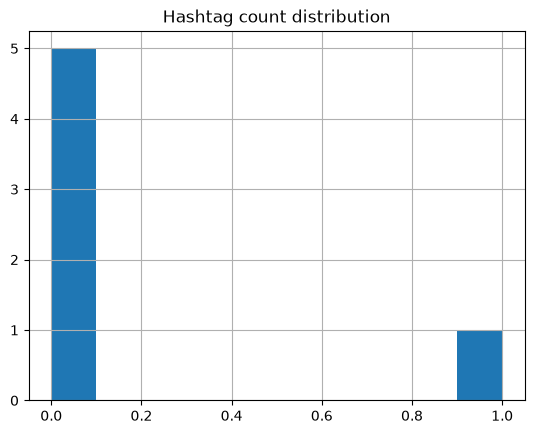

In [27]:
# Function that returns numner of hashtags in a string
def count_hashtags(string):
	# Split the string into words
    words = string.split()
    
    # Create a list of words that are hashtags
    hashtags = [word for word in words if word.startswith('#')]
    
    # Return number of hashtags
    return(len(hashtags))

# Create a feature hashtag_count and display distribution
tweets['hashtag_count'] = tweets['content'].apply(count_hashtags)
tweets['hashtag_count'].hist()
plt.title('Hashtag count distribution')
plt.show()

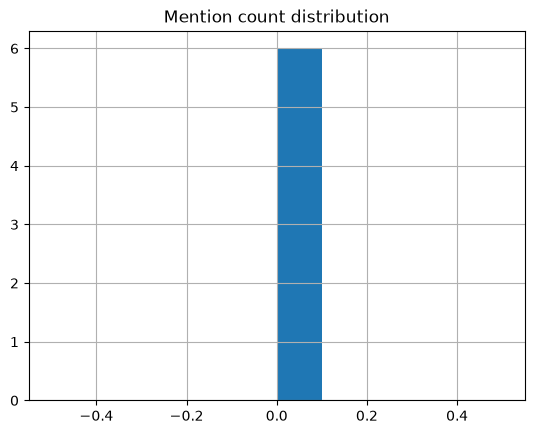

In [28]:
# Function that returns number of mentions in a string
def count_mentions(string):
	# Split the string into words
    words = string.split()
    
    # Create a list of words that are mentions
    mentions = [word for word in words if word.startswith('@')]
    
    # Return number of mentions
    return(len(mentions))

# Create a feature mention_count and display distribution
tweets['mention_count'] = tweets['content'].apply(count_mentions)
tweets['mention_count'].hist()
plt.title('Mention count distribution')
plt.show()